In [28]:
import requests
import pandas as pd

EIA_API_KEY = "bkr7wJprPJ8FDWtMGPpHFTmBCcFKk6qgTBQgdBQM"

# Using the series endpoint or querying by series ID directly is more reliable for specific series like Europe Brent Spot Price FOB (RBRTE)
url = "https://api.eia.gov/v2/petroleum/pri/spt/data/"

# Spot price of Brent is typically under series: 'RBRTE'
params = {
    "api_key": EIA_API_KEY,
    "frequency": "daily",
    "data[0]": "value",
    "facets[series][]": "RBRTE",
    "sort[0][column]": "period",
    "sort[0][direction]": "desc",
    "length": 100
}

response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

oil_df = pd.DataFrame(data["response"]["data"])

if not oil_df.empty:
    oil_df["value"] = pd.to_numeric(
        oil_df["value"], errors="coerce"
    )
    oil_df["period"] = pd.to_datetime(oil_df["period"])

oil_df.head()

,period,duoarea,area-name,product,product-name,process,process-name,series,series-description,value,units
0,2026-11-17,ZEU,NA,EPCBRENT,UK Brent Crude Oil,PF4,Spot Price FOB,RBRTE,Europe Brent Spot Price FOB (Dollars per Barrel),92.94,$/BBL
1,2026-11-16,ZEU,NA,EPCBRENT,UK Brent Crude Oil,PF4,Spot Price FOB,RBRTE,Europe Brent Spot Price FOB (Dollars per Barrel),92.90,$/BBL
2,2026-11-13,ZEU,NA,EPCBRENT,UK Brent Crude Oil,PF4,Spot Price FOB,RBRTE,Europe Brent Spot Price FOB (Dollars per Barrel),95.17,$/BBL
3,2026-11-12,ZEU,NA,EPCBRENT,UK Brent Crude Oil,PF4,Spot Price FOB,RBRTE,Europe Brent Spot Price FOB (Dollars per Barrel),95.42,$/BBL
4,2026-11-11,ZEU,NA,EPCBRENT,UK Brent Crude Oil,PF4,Spot Price FOB,RBRTE,Europe Brent Spot Price FOB (Dollars per Barrel),92.14,$/BBL


In [29]:
oil_df.info()
print(oil_df.shape)
oil_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   period              100 non-null    datetime64[ns]
 1   duoarea             100 non-null    object        
 2   area-name           100 non-null    object        
 3   product             100 non-null    object        
 4   product-name        100 non-null    object        
 5   process             100 non-null    object        
 6   process-name        100 non-null    object        
 7   series              100 non-null    object        
 8   series-description  100 non-null    object        
 9   value               100 non-null    float64       
 10  units               100 non-null    object        
dtypes: datetime64[ns](1), float64(1), object(9)
memory usage: 8.7+ KB
(100, 11)


,period,value
count,100,100.000000
mean,2026-09-07 16:19:12,102.081400
min,2026-06-30 00:00:00,68.530000
25%,2026-08-03 18:00:00,90.175000
50%,2026-09-08 12:00:00,96.935000
75%,2026-10-13 06:00:00,118.915000
max,2026-11-17 00:00:00,135.510000
std,NaN,17.683522


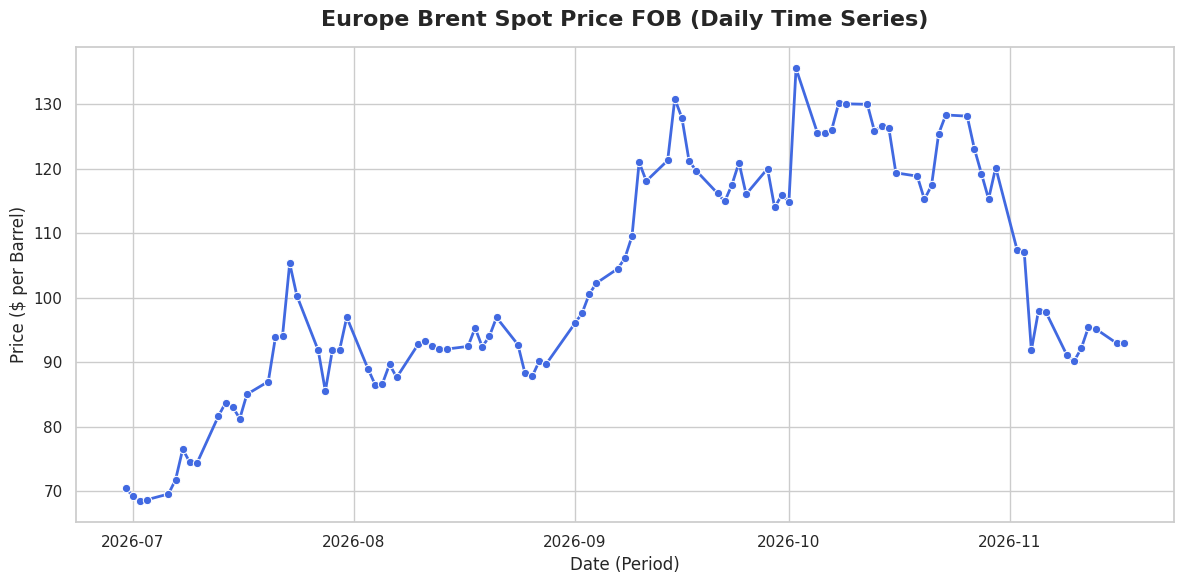

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure plot style and size
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 6))

# Plot the line chart
sns.lineplot(
    data=oil_df,
    x="period",
    y="value",
    marker="o",
    color="royalblue",
    linewidth=2
)

# Configure titles and labels
plt.title("Europe Brent Spot Price FOB (Daily Time Series)", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Date (Period)", fontsize=12)
plt.ylabel("Price ($ per Barrel)", fontsize=12)

# Show the plot
plt.tight_layout()
plt.show()

### 1. Missing Value and Completeness Check
Before jumping into calculations, I must verify if there are any gaps or null values.

In [31]:
# Calculate missing values and check date ranges
missing_count = oil_df['value'].isna().sum()
total_records = len(oil_df)
min_date = oil_df['period'].min()
max_date = oil_df['period'].max()

print(f"Dataset coverage: {min_date.strftime('%Y-%m-%d')} to {max_date.strftime('%Y-%m-%d')}")
print(f"Missing values in 'value': {missing_count} out of {total_records} rows ({missing_count / total_records * 100:.1f}%)")

Dataset coverage: 2026-06-30 to 2026-11-17
Missing values in 'value': 0 out of 100 rows (0.0%)


### 2. Price Distribution Analysis
Let's analyze how the prices are distributed. I will plot a Histogram with a Kernel Density Estimate (KDE) to see where the prices are concentrated.

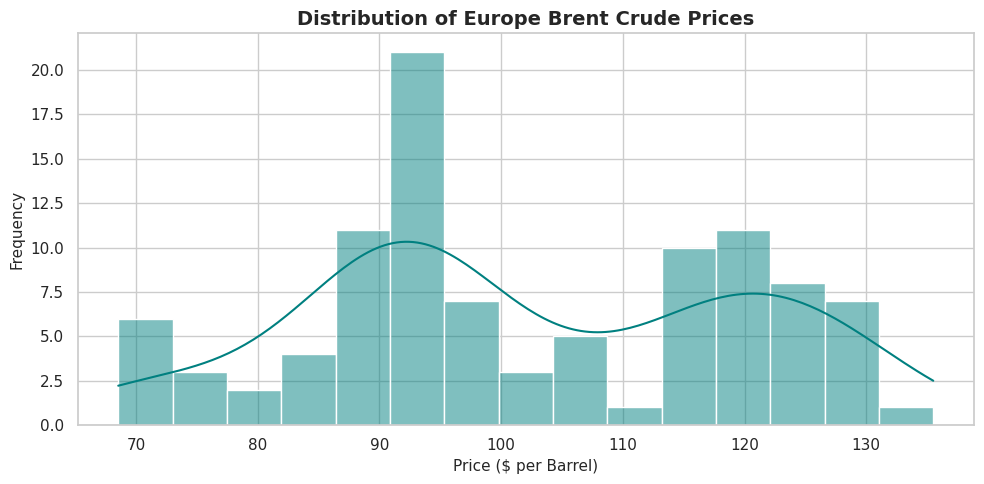

In [32]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=oil_df, x="value", kde=True, color="teal", bins=15, ax=ax)
plt.title("Distribution of Europe Brent Crude Prices", fontsize=14, fontweight="bold")
plt.xlabel("Price ($ per Barrel)", fontsize=11)
plt.ylabel("Frequency", fontsize=11)
plt.tight_layout()
plt.show()

### 3. Moving Averages (Trend Smoothing)
To smooth out short-term fluctuations and identify structural price trends, we calculate the 7-day and 30-day Simple Moving Averages (SMA). Since our retrieved data is currently sorted in descending order (newest first), we must sort it ascendingly (oldest first) before applying the `.rolling()` window function.

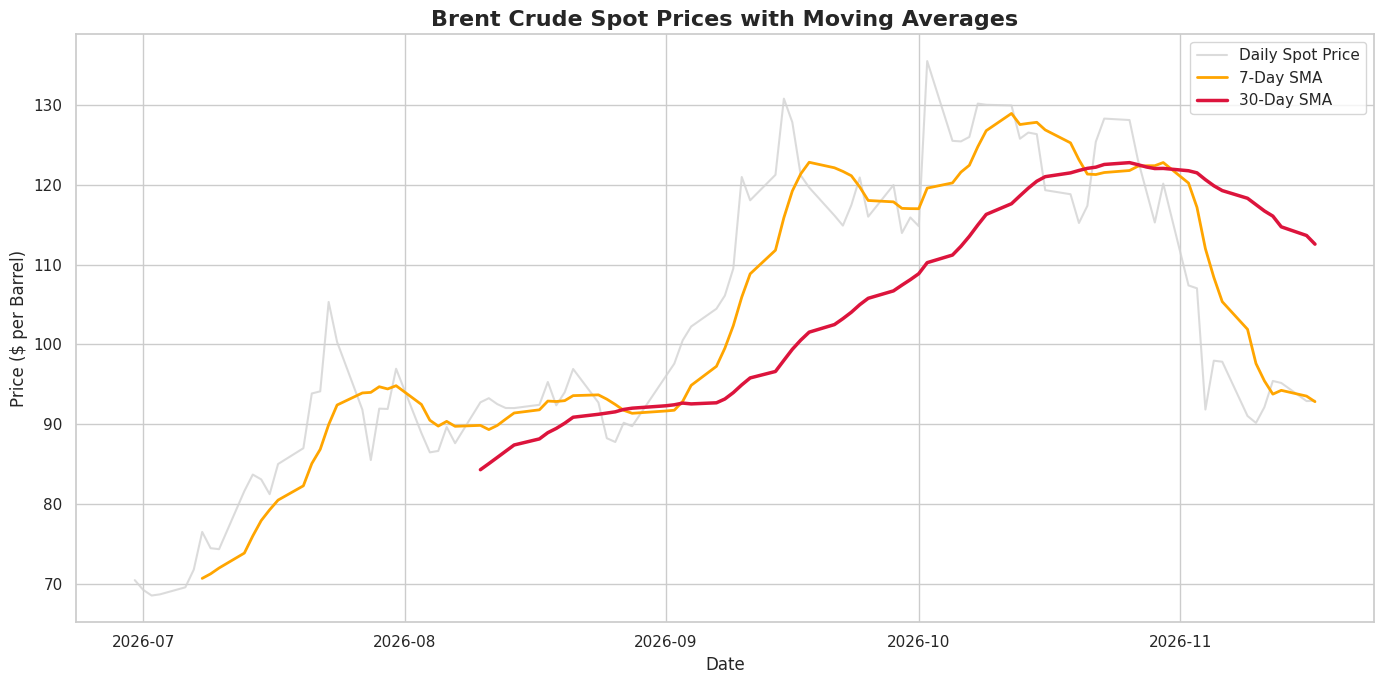

In [33]:
# Sort chronologically (oldest first) to compute rolling calculations correctly
oil_df_sorted = oil_df.sort_values("period").copy()

# Compute moving averages
oil_df_sorted['SMA_7'] = oil_df_sorted['value'].rolling(window=7).mean()
oil_df_sorted['SMA_30'] = oil_df_sorted['value'].rolling(window=30).mean()

# Visualize original price alongside moving averages
fig, ax = plt.subplots(figsize=(14, 7))
sns.lineplot(data=oil_df_sorted, x="period", y="value", label="Daily Spot Price", color="lightgray", alpha=0.8, ax=ax)
sns.lineplot(data=oil_df_sorted, x="period", y="SMA_7", label="7-Day SMA", color="orange", linewidth=2, ax=ax)
sns.lineplot(data=oil_df_sorted, x="period", y="SMA_30", label="30-Day SMA", color="crimson", linewidth=2.5, ax=ax)

plt.title("Brent Crude Spot Prices with Moving Averages", fontsize=16, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Price ($ per Barrel)", fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### 4. Extreme Price Shifts
Lastly, let's find the days where the Brent crude prices saw the largest single-day dollar changes.

In [34]:
# Calculate day-over-day price differences
oil_df_sorted['daily_change'] = oil_df_sorted['value'].diff()

# Top 3 largest gains
largest_gains = oil_df_sorted.nlargest(3, 'daily_change')[['period', 'value', 'daily_change']]

# Top 3 largest drops
largest_drops = oil_df_sorted.nsmallest(3, 'daily_change')[['period', 'value', 'daily_change']]

print("--- Top 3 Largest Single-Day Price Gains ---")
display(largest_gains)

print("\n--- Top 3 Largest Single-Day Price Drops ---")
display(largest_drops)

--- Top 3 Largest Single-Day Price Gains ---


,period,value,daily_change
32,2026-10-02,135.51,20.69
48,2026-09-10,120.98,11.47
82,2026-07-23,105.32,11.20



--- Top 3 Largest Single-Day Price Drops ---


,period,value,daily_change
9,2026-11-04,91.84,-15.19
11,2026-11-02,107.39,-12.76
31,2026-10-05,125.51,-10.00


### 5. Rolling Volatility Analysis
Volatility measures the dispersion of returns or prices over a set period. We calculate the rolling standard deviation over both short-term (7-day) and medium-term (30-day) horizons to see when market uncertainty peaked.

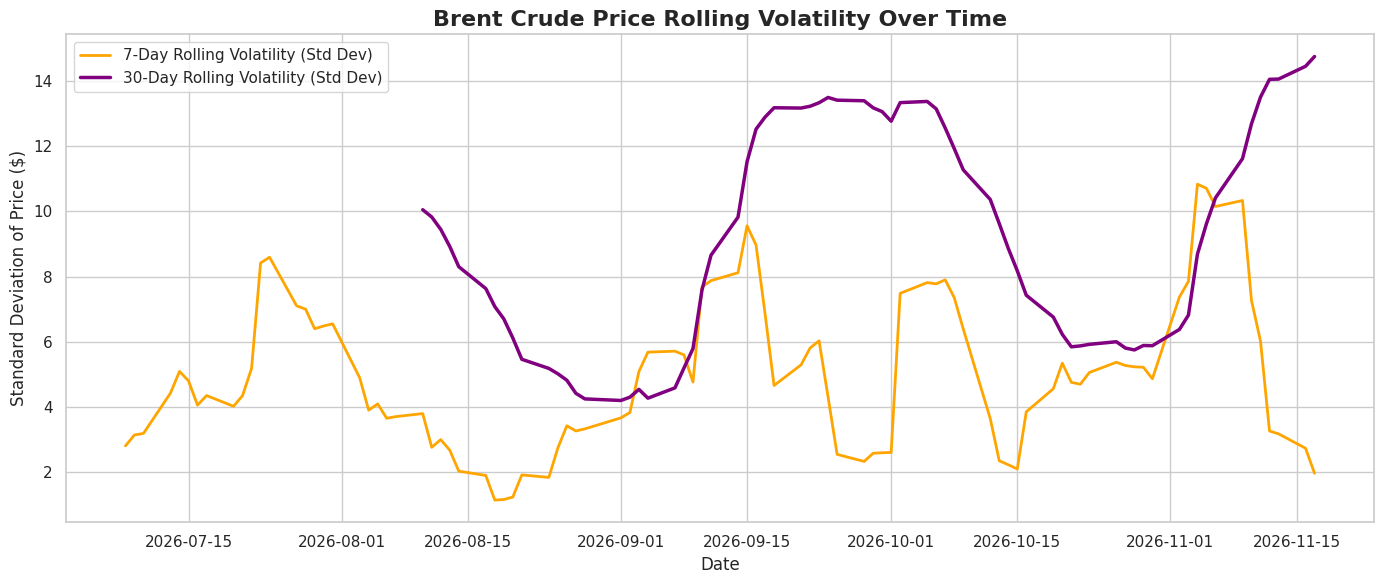

In [35]:
# Calculate rolling standard deviation
oil_df_sorted['Volatility_7d'] = oil_df_sorted['value'].rolling(window=7).std()
oil_df_sorted['Volatility_30d'] = oil_df_sorted['value'].rolling(window=30).std()

# Visualize rolling volatility
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=oil_df_sorted, x="period", y="Volatility_7d", label="7-Day Rolling Volatility (Std Dev)", color="orange", linewidth=2, ax=ax)
sns.lineplot(data=oil_df_sorted, x="period", y="Volatility_30d", label="30-Day Rolling Volatility (Std Dev)", color="purple", linewidth=2.5, ax=ax)

plt.title("Brent Crude Price Rolling Volatility Over Time", fontsize=16, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Standard Deviation of Price ($)", fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [37]:
from google.colab import files

# Save the sorted oil price DataFrame to a CSV file
csv_filename = "brent_crude_spot_prices.csv"
oil_df_sorted.to_csv(csv_filename, index=False)
print(f"Dataset successfully saved to {csv_filename}!")

# Trigger the download to your local machine
#files.download(csv_filename)

Dataset successfully saved to brent_crude_spot_prices.csv!


--- Correlation Matrix ---


,value,Volatility_7d,Volatility_30d
value,1.000000,0.256002,0.234477
Volatility_7d,0.256002,1.000000,0.170409
Volatility_30d,0.234477,0.170409,1.000000


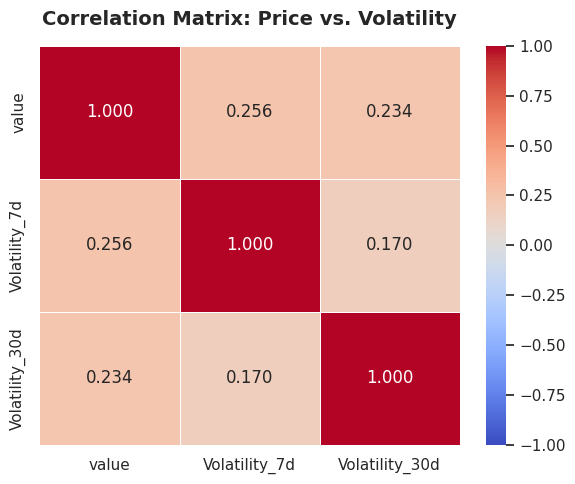

In [38]:
# Select relevant columns for the correlation matrix
corr_cols = ['value', 'Volatility_7d', 'Volatility_30d']
corr_matrix = oil_df_sorted[corr_cols].corr()

# Display the numerical correlation matrix
print("--- Correlation Matrix ---")
display(corr_matrix)

# Plot the correlation matrix as a heatmap
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".3f",
    linewidths=0.5,
    ax=ax
)
plt.title("Correlation Matrix: Price vs. Volatility", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

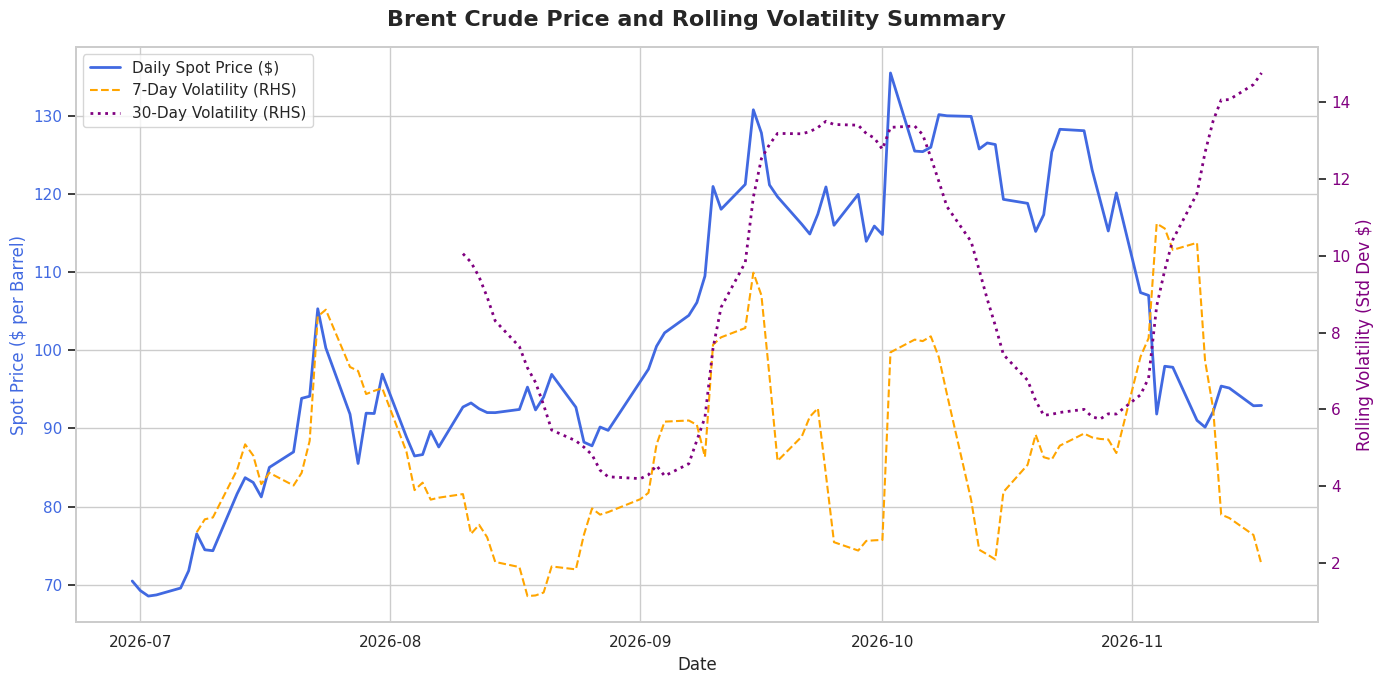

In [41]:
# Create a combined summary plot with dual y-axes to handle different scales
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot Price on the primary y-axis (left)
sns.lineplot(
    data=oil_df_sorted,
    x="period",
    y="value",
    label="Daily Spot Price ($)",
    color="royalblue",
    linewidth=2,
    ax=ax1
)
ax1.set_ylabel("Spot Price ($ per Barrel)", color="royalblue", fontsize=12)
ax1.tick_params(axis='y', labelcolor="royalblue")
ax1.set_xlabel("Date", fontsize=12)

# Create a secondary y-axis on the right for Volatility
ax2 = ax1.twinx()
sns.lineplot(
    data=oil_df_sorted,
    x="period",
    y="Volatility_7d",
    label="7-Day Volatility (RHS)",
    color="orange",
    linewidth=1.5,
    linestyle="--",
    ax=ax2
)
sns.lineplot(
    data=oil_df_sorted,
    x="period",
    y="Volatility_30d",
    label="30-Day Volatility (RHS)",
    color="purple",
    linewidth=2,
    linestyle=":",
    ax=ax2
)
ax2.set_ylabel("Rolling Volatility (Std Dev $)", color="purple", fontsize=12)
ax2.tick_params(axis='y', labelcolor="purple")
ax2.grid(False) # Turn off grid for the secondary axis to keep it clean

# Configure legend and title
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.get_legend().remove() # Remove single-axis legend
plt.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=11)

plt.title("Brent Crude Price and Rolling Volatility Summary", fontsize=16, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

In [39]:
!pip install -q reportlab